In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0012706.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0010192.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0010017.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0013000.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0013166.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0003308.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0012332.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0014291.jpg
/kaggle/

In [2]:
from pathlib import Path

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")

folders = [
    "src",
    "results",
    "outputs/cleaned",
    "outputs/masks",
    "outputs/figures"
]

files = [
    "src/__init__.py",
    "src/config.py",
    "src/quality.py",
    "src/hair_removal.py",
    "src/local_artifacts.py",
    "src/photometric.py",
    "src/sharpness.py",
    "src/peripheral.py",
    "src/segmentation.py",
    "src/pipeline.py",
    "README.md",
    "requirements.txt"
]

for folder in folders:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)

for file in files:
    path = PROJECT / file
    path.touch(exist_ok=True)

print("Architecture créée avec succès !")
print("Emplacement :", PROJECT)

Architecture créée avec succès !
Emplacement : /kaggle/working/ISIC2018_pipeline_adaptatif


In [3]:
%%writefile /kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_removal.py

import cv2
import numpy as np

def element_ligne(taille, angle):
    kernel = np.zeros((taille, taille), dtype=np.uint8)
    c = taille // 2

    rad = np.deg2rad(angle)
    dx = round(c * np.cos(rad))
    dy = round(c * np.sin(rad))

    cv2.line(kernel, (c-dx, c-dy), (c+dx, c+dy), 1, 1)

    return kernel


def dullrazor(image_rgb, taille=17, seuil=18):
    h, w = image_rgb.shape[:2]

    scale = min(1.0, 768 / w)

    if scale < 1:
        image_rgb = cv2.resize(
            image_rgb,
            (round(w * scale), round(h * scale)),
            interpolation=cv2.INTER_AREA
        )

    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    response = np.zeros_like(gray)

    for angle in [0, 45, 90, 135]:

        kernel = element_ligne(taille, angle)

        fermeture = cv2.morphologyEx(
            gray, cv2.MORPH_CLOSE, kernel
        )

        difference = cv2.subtract(fermeture, gray)

        response = np.maximum(response, difference)

    _, masque = cv2.threshold(
        response, seuil, 255, cv2.THRESH_BINARY
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    masque = cv2.dilate(masque, kernel, iterations=1)

    image_nettoyee = cv2.inpaint(
        image_rgb,
        masque,
        inpaintRadius=3,
        flags=cv2.INPAINT_TELEA
    )

    return image_rgb, response, masque, image_nettoyee

Overwriting /kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_removal.py


In [4]:
from pathlib import Path

fichier = Path(
    "/kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_removal.py"
)

print("Fichier créé :", fichier.exists())

Fichier créé : True


In [5]:
import sys

PROJECT = "/kaggle/working/ISIC2018_pipeline_adaptatif"

sys.path.insert(0, PROJECT)

from src.hair_removal import dullrazor

print("Fonction DullRazor importée avec succès !")

Fonction DullRazor importée avec succès !


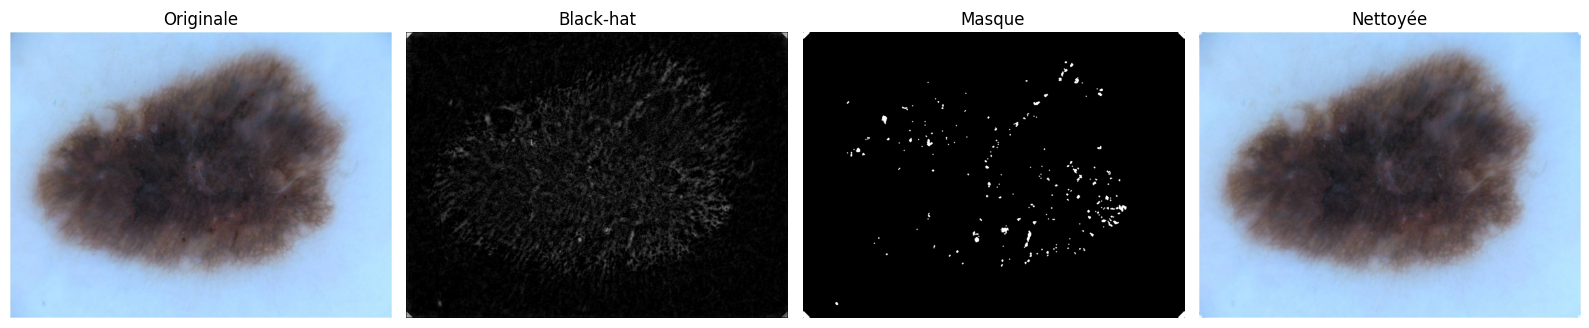

In [6]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

IMAGES_DIR = Path(
    "/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/"
    "ISIC2018_Task1-2_Training_Input"
)

image_path = sorted(IMAGES_DIR.glob("*.jpg"))[0]

image_bgr = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

originale, response, masque, nettoyee = dullrazor(image_rgb)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

images = [originale, response, masque, nettoyee]
titres = ["Originale", "Black-hat", "Masque", "Nettoyée"]

for ax, img, titre in zip(axes, images, titres):
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.set_title(titre)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
from pathlib import Path
import pandas as pd

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")
RESULTS = PROJECT / "results"
REFERENCES = PROJECT / "references"

RESULTS.mkdir(parents=True, exist_ok=True)
REFERENCES.mkdir(parents=True, exist_ok=True)

DATASET = Path(
    "/kaggle/input/datasets/tschandl/"
    "isic2018-challenge-task1-data-segmentation"
)

IMAGES_DIR = DATASET / "ISIC2018_Task1-2_Training_Input"

images = sorted(IMAGES_DIR.glob("*.jpg"))

print("Images ISIC 2018 :", len(images))
print("Dossier des résultats :", RESULTS)

Images ISIC 2018 : 2594
Dossier des résultats : /kaggle/working/ISIC2018_pipeline_adaptatif/results


In [8]:
import subprocess

repo = REFERENCES / "debiasing-skin"

if not repo.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/alceubissoto/debiasing-skin.git",
            str(repo)
        ],
        check=True
    )

print("Dépôt téléchargé :", repo.exists())

Cloning into '/kaggle/working/ISIC2018_pipeline_adaptatif/references/debiasing-skin'...


Dépôt téléchargé : True


In [9]:
annotations_dir = repo / "artefacts-annotation"

if not annotations_dir.exists():
    raise FileNotFoundError(
        "Dossier artefacts-annotation introuvable"
    )

annotation_files = [
    p for p in annotations_dir.rglob("*")
    if p.is_file()
]

print("Nombre de fichiers :", len(annotation_files))

for path in annotation_files[:40]:
    print(path.relative_to(annotations_dir))

Nombre de fichiers : 2
atlas_bias.csv
isic_bias.csv


In [10]:
csv_files = list(annotations_dir.rglob("*.csv"))

for fichier in csv_files[:10]:
    print("\nFichier :", fichier.name)

    df = pd.read_csv(fichier)
    print("Dimensions :", df.shape)
    print("Colonnes :", df.columns.tolist())

    display(df.head(3))


Fichier : atlas_bias.csv
Dimensions : (872, 1)
Colonnes : [';image;dark_corner;hair;gel_border;gel_bubble;ruler;ink;patches;label;label_string']


,;image;dark_corner;hair;gel_border;gel_bubble;ruler;ink;patches;label;label_string
0,0;aal002;0;1;0;1;0;0;0;1.0;malignant
1,1;aal002bis;0;1;0;1;0;0;0;1.0;malignant
2,2;aal004;0;0;0;1;0;0;0;0.0;benign



Fichier : isic_bias.csv
Dimensions : (2594, 1)
Colonnes : [';image;dark_corner;hair;gel_border;gel_bubble;ruler;ink;patches;label;label_string']


,;image;dark_corner;hair;gel_border;gel_bubble;ruler;ink;patches;label;label_string
0,0;ISIC_0000000.png;0;0;0;0;0;0;0;0;benign
1,1;ISIC_0000001.png;0;1;0;1;0;0;0;0;benign
2,2;ISIC_0000003.png;0;1;0;1;0;0;0;0;benign


In [11]:
catalogue = pd.DataFrame({
    "image_id": [p.stem for p in images],
    "image_path": [str(p) for p in images]
})

catalogue = catalogue.sort_values("image_id").reset_index(drop=True)

catalogue.to_csv(
    RESULTS / "isic2018_image_catalog.csv",
    index=False
)

display(catalogue.head())
print("Catalogue enregistré :", len(catalogue), "images")

,image_id,image_path
0,ISIC_0000000,/kaggle/input/datasets/tschandl/isic2018-chall...
1,ISIC_0000001,/kaggle/input/datasets/tschandl/isic2018-chall...
2,ISIC_0000003,/kaggle/input/datasets/tschandl/isic2018-chall...
3,ISIC_0000004,/kaggle/input/datasets/tschandl/isic2018-chall...
4,ISIC_0000006,/kaggle/input/datasets/tschandl/isic2018-chall...


Catalogue enregistré : 2594 images


In [12]:
from pathlib import Path

dossier = Path(
    "/kaggle/working/ISIC2018_pipeline_adaptatif/"
    "references/debiasing-skin/artefacts-annotation"
)

for fichier in dossier.rglob("*"):
    if fichier.is_file():
        print(fichier.name)

atlas_bias.csv
isic_bias.csv


In [13]:
from pathlib import Path

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")

print("Projet existe :", PROJECT.exists())

if PROJECT.exists():
    for path in sorted(PROJECT.rglob("*")):
        print(path.relative_to(PROJECT))
else:
    print("Architecture introuvable dans cette session.")

Projet existe : True
README.md
outputs
outputs/cleaned
outputs/figures
outputs/masks
references
references/debiasing-skin
references/debiasing-skin/.git
references/debiasing-skin/.git/HEAD
references/debiasing-skin/.git/branches
references/debiasing-skin/.git/config
references/debiasing-skin/.git/description
references/debiasing-skin/.git/hooks
references/debiasing-skin/.git/hooks/applypatch-msg.sample
references/debiasing-skin/.git/hooks/commit-msg.sample
references/debiasing-skin/.git/hooks/fsmonitor-watchman.sample
references/debiasing-skin/.git/hooks/post-update.sample
references/debiasing-skin/.git/hooks/pre-applypatch.sample
references/debiasing-skin/.git/hooks/pre-commit.sample
references/debiasing-skin/.git/hooks/pre-merge-commit.sample
references/debiasing-skin/.git/hooks/pre-push.sample
references/debiasing-skin/.git/hooks/pre-rebase.sample
references/debiasing-skin/.git/hooks/pre-receive.sample
references/debiasing-skin/.git/hooks/prepare-commit-msg.sample
references/debiasi

In [14]:
from pathlib import Path

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")

folders = [
    "src",
    "results",
    "references",
    "outputs/cleaned",
    "outputs/masks",
    "outputs/figures"
]

for folder in folders:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)

modules = [
    "__init__.py",
    "quality.py",
    "hair_removal.py",
    "local_artifacts.py",
    "photometric.py",
    "sharpness.py",
    "peripheral.py",
    "pipeline.py",
    "segmentation.py"
]

for module in modules:
    (PROJECT / "src" / module).touch(exist_ok=True)

(PROJECT / "README.md").touch(exist_ok=True)

print("Architecture créée :", PROJECT)

Architecture créée : /kaggle/working/ISIC2018_pipeline_adaptatif


In [15]:
from pathlib import Path

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")

for fichier in sorted((PROJECT / "src").glob("*.py")):
    taille = fichier.stat().st_size
    print(f"{fichier.name:25} : {taille} octets")

__init__.py               : 0 octets
config.py                 : 0 octets
hair_removal.py           : 1378 octets
local_artifacts.py        : 0 octets
peripheral.py             : 0 octets
photometric.py            : 0 octets
pipeline.py               : 0 octets
quality.py                : 0 octets
segmentation.py           : 0 octets
sharpness.py              : 0 octets


In [16]:
%%writefile /kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_removal.py

import cv2
import numpy as np


def element_ligne(taille: int, angle: float) -> np.ndarray:
    """Créer un élément structurant linéaire selon une orientation."""

    if taille < 3 or taille % 2 == 0:
        raise ValueError("taille doit être impaire et >= 3")

    kernel = np.zeros((taille, taille), dtype=np.uint8)

    c = taille // 2
    rad = np.deg2rad(angle)

    dx = round(c * np.cos(rad))
    dy = round(c * np.sin(rad))

    cv2.line(
        kernel,
        (c - dx, c - dy),
        (c + dx, c + dy),
        1,
        1
    )

    return kernel


def dullrazor(image_rgb: np.ndarray, taille: int = 17, seuil: int = 18):
    """
    Détection des poils candidats par Black-hat multi-orientations
    et reconstruction par inpainting de Telea.

    Retour :
        image_rgb, response, masque, image_nettoyee
    """

    if (
        image_rgb is None
        or image_rgb.ndim != 3
        or image_rgb.shape[2] != 3
        or image_rgb.dtype != np.uint8
    ):
        raise ValueError("L'image doit être RGB uint8.")

    h, w = image_rgb.shape[:2]

    if h == 0 or w == 0:
        raise ValueError("Image vide")

    scale = min(1.0, 768 / w)

    if scale < 1:
        image_rgb = cv2.resize(
            image_rgb,
            (round(w * scale), round(h * scale)),
            interpolation=cv2.INTER_AREA
        )

    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    response = np.zeros_like(gray)

    for angle in [0, 45, 90, 135]:

        kernel = element_ligne(taille, angle)

        fermeture = cv2.morphologyEx(
            gray,
            cv2.MORPH_CLOSE,
            kernel
        )

        difference = cv2.subtract(fermeture, gray)
        response = np.maximum(response, difference)

    _, masque = cv2.threshold(
        response,
        seuil,
        255,
        cv2.THRESH_BINARY
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (3, 3)
    )

    masque = cv2.dilate(
        masque,
        kernel,
        iterations=1
    )

    image_nettoyee = cv2.inpaint(
        image_rgb,
        masque,
        inpaintRadius=3,
        flags=cv2.INPAINT_TELEA
    )

    return image_rgb, response, masque, image_nettoyee

Overwriting /kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_removal.py


In [17]:
from pathlib import Path

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")
fichier = PROJECT / "src" / "hair_removal.py"

print("Fichier existe :", fichier.exists())
print("Taille :", fichier.stat().st_size, "octets")

Fichier existe : True
Taille : 2217 octets


In [18]:
import sys

sys.path.insert(0, str(PROJECT))

from src.hair_removal import dullrazor, element_ligne

print("Importation réussie !")

Importation réussie !


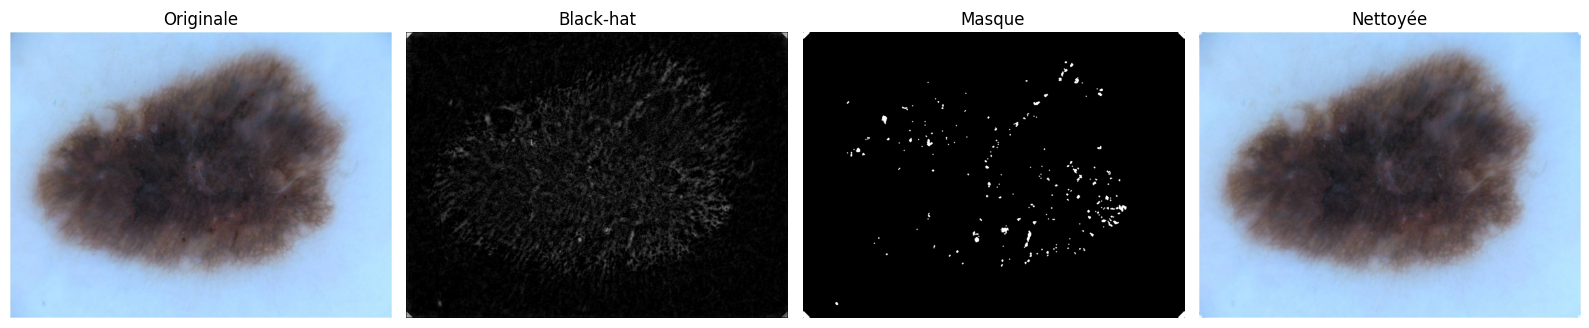

In [19]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

IMAGES_DIR = Path(
    "/kaggle/input/datasets/tschandl/"
    "isic2018-challenge-task1-data-segmentation/"
    "ISIC2018_Task1-2_Training_Input"
)

images = sorted(IMAGES_DIR.glob("*.jpg"))
assert images, "Aucune image trouvée : vérifier le chemin ISIC."

image_bgr = cv2.imread(str(images[0]))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

originale, reponse, masque, nettoyee = dullrazor(image_rgb)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, img, titre in zip(
    axes,
    [originale, reponse, masque, nettoyee],
    ["Originale", "Black-hat", "Masque", "Nettoyée"]
):
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.set_title(titre)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [20]:
import shutil

backup = shutil.make_archive(
    "/kaggle/working/ISIC2018_pipeline_backup",
    "zip",
    root_dir="/kaggle/working",
    base_dir="ISIC2018_pipeline_adaptatif"
)

print("Archive créée :", backup)

Archive créée : /kaggle/working/ISIC2018_pipeline_backup.zip


In [21]:
from pathlib import Path

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")

REFERENCES = PROJECT / "references"
RESULTS = PROJECT / "results"

REFERENCES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

print("Dossiers prêts")

Dossiers prêts


In [22]:
import subprocess

REPO = REFERENCES / "debiasing-skin"

if not REPO.exists():
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/alceubissoto/debiasing-skin.git",
        str(REPO)
    ], check=True)

ANNOTATIONS = REPO / "artefacts-annotation"

print("Annotations trouvées :", ANNOTATIONS.exists())

Annotations trouvées : True


In [23]:
files = sorted([
    p for p in ANNOTATIONS.rglob("*")
    if p.is_file()
])

for p in files:
    print(p.relative_to(ANNOTATIONS))

atlas_bias.csv
isic_bias.csv


In [24]:
from pathlib import Path
import pandas as pd

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")
RESULTS = PROJECT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

ANNOTATIONS = (
    PROJECT / "references/debiasing-skin/artefacts-annotation"
)

csv_path = ANNOTATIONS / "isic_bias.csv"

# Le fichier utilise le point-virgule comme séparateur.
annotations = pd.read_csv(csv_path, sep=";")

# Supprimer les colonnes d'index non pertinentes
annotations = annotations.loc[
    :, ~annotations.columns.str.startswith("Unnamed")
]

# Les images dans les annotations sont en .png.
# Nos images Kaggle sont en .jpg.
# Nous utilisons donc l'identifiant sans extension.
annotations["image_id"] = annotations["image"].apply(
    lambda name: Path(name).stem
)

print("Nombre d'annotations :", len(annotations))
print("Colonnes :", annotations.columns.tolist())

display(annotations.head())

Nombre d'annotations : 2594
Colonnes : ['image', 'dark_corner', 'hair', 'gel_border', 'gel_bubble', 'ruler', 'ink', 'patches', 'label', 'label_string', 'image_id']


,image,dark_corner,hair,gel_border,gel_bubble,ruler,ink,patches,label,label_string,image_id
0,ISIC_0000000.png,0,0,0,0,0,0,0,0,benign,ISIC_0000000
1,ISIC_0000001.png,0,1,0,1,0,0,0,0,benign,ISIC_0000001
2,ISIC_0000003.png,0,1,0,1,0,0,0,0,benign,ISIC_0000003
3,ISIC_0000004.png,1,1,0,1,1,0,0,1,malignant,ISIC_0000004
4,ISIC_0000006.png,1,0,0,0,0,0,0,0,benign,ISIC_0000006


In [25]:
IMAGES_DIR = Path(
    "/kaggle/input/datasets/tschandl/"
    "isic2018-challenge-task1-data-segmentation/"
    "ISIC2018_Task1-2_Training_Input"
)

image_paths = sorted(IMAGES_DIR.glob("*.jpg"))

catalogue = pd.DataFrame({
    "image_id": [p.stem for p in image_paths],
    "image_path": [str(p) for p in image_paths]
})

# Vérification des doublons
assert catalogue["image_id"].is_unique
assert annotations["image_id"].is_unique

# Jointure des deux datasets
df = catalogue.merge(
    annotations,
    on="image_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Images ISIC :", len(catalogue))
print("Annotations :", len(annotations))

print("\nCorrespondances :")
print(df["_merge"].value_counts())

df = df.drop(columns=["_merge"])

display(df.head())

Images ISIC : 2594
Annotations : 2594

Correspondances :
_merge
both          2594
left_only        0
right_only       0
Name: count, dtype: int64


,image_id,image_path,image,dark_corner,hair,gel_border,gel_bubble,ruler,ink,patches,label,label_string
0,ISIC_0000000,/kaggle/input/datasets/tschandl/isic2018-chall...,ISIC_0000000.png,0,0,0,0,0,0,0,0,benign
1,ISIC_0000001,/kaggle/input/datasets/tschandl/isic2018-chall...,ISIC_0000001.png,0,1,0,1,0,0,0,0,benign
2,ISIC_0000003,/kaggle/input/datasets/tschandl/isic2018-chall...,ISIC_0000003.png,0,1,0,1,0,0,0,0,benign
3,ISIC_0000004,/kaggle/input/datasets/tschandl/isic2018-chall...,ISIC_0000004.png,1,1,0,1,1,0,0,1,malignant
4,ISIC_0000006,/kaggle/input/datasets/tschandl/isic2018-chall...,ISIC_0000006.png,1,0,0,0,0,0,0,0,benign


In [26]:
import pandas as pd

artefacts = [
    "hair",
    "gel_bubble",
    "gel_border",
    "ruler",
    "dark_corner",
    "ink",
    "patches"
]

# Vérifier la présence et les valeurs des annotations
for col in artefacts:
    df[col] = pd.to_numeric(df[col], errors="coerce")

    valeurs = set(df[col].dropna().unique())
    assert valeurs.issubset({0, 1}), f"Valeurs invalides : {col}"

# Conserver uniquement les informations utiles
reference = df[
    ["image_id", "image_path"] + artefacts
].copy()

reference.to_csv(
    RESULTS / "artifact_labels_reference.csv",
    index=False
)

# Construire les cinq familles de problèmes
quality = reference[["image_id", "image_path"]].copy()

# C1 : Poils
quality["C1_hair"] = reference["hair"].astype("Int64")

# C2 : Bulles / bordures de gel
# Cela ne couvre pas tous les reflets.
quality["C2_local_artifacts_partial"] = (
    reference[["gel_bubble", "gel_border"]]
    .max(axis=1)
    .astype("Int64")
)

# C3 : Qualité photométrique non encore évaluée
quality["C3_photometric"] = pd.Series(
    pd.NA, index=quality.index, dtype="Int64"
)

# C4 : Flou / bruit non encore évalués
quality["C4_sharpness"] = pd.Series(
    pd.NA, index=quality.index, dtype="Int64"
)

# C5 : Règles / coins sombres
quality["C5_peripheral_partial"] = (
    reference[["ruler", "dark_corner"]]
    .max(axis=1)
    .astype("Int64")
)

quality.to_csv(
    RESULTS / "image_quality_labels.csv",
    index=False
)

print("Classification enregistrée !")
display(quality.head(10))

Classification enregistrée !


,image_id,image_path,C1_hair,C2_local_artifacts_partial,C3_photometric,C4_sharpness,C5_peripheral_partial
0,ISIC_0000000,/kaggle/input/datasets/tschandl/isic2018-chall...,0,0,<NA>,<NA>,0
1,ISIC_0000001,/kaggle/input/datasets/tschandl/isic2018-chall...,1,1,<NA>,<NA>,0
2,ISIC_0000003,/kaggle/input/datasets/tschandl/isic2018-chall...,1,1,<NA>,<NA>,0
3,ISIC_0000004,/kaggle/input/datasets/tschandl/isic2018-chall...,1,1,<NA>,<NA>,1
4,ISIC_0000006,/kaggle/input/datasets/tschandl/isic2018-chall...,0,0,<NA>,<NA>,1
5,ISIC_0000007,/kaggle/input/datasets/tschandl/isic2018-chall...,0,0,<NA>,<NA>,1
6,ISIC_0000008,/kaggle/input/datasets/tschandl/isic2018-chall...,0,0,<NA>,<NA>,0
7,ISIC_0000009,/kaggle/input/datasets/tschandl/isic2018-chall...,1,0,<NA>,<NA>,1
8,ISIC_0000011,/kaggle/input/datasets/tschandl/isic2018-chall...,1,0,<NA>,<NA>,1
9,ISIC_0000012,/kaggle/input/datasets/tschandl/isic2018-chall...,1,1,<NA>,<NA>,1


In [27]:
classes = [
    "C1_hair",
    "C2_local_artifacts_partial",
    "C3_photometric",
    "C4_sharpness",
    "C5_peripheral_partial"
]

summary = pd.DataFrame({
    "classe": classes,
    "images_evaluees": [
        quality[c].notna().sum() for c in classes
    ],
    "images_positives": [
        (quality[c] == 1).sum() for c in classes
    ]
})

summary.to_csv(
    RESULTS / "classification_summary.csv",
    index=False
)

display(summary)

,classe,images_evaluees,images_positives
0,C1_hair,2594,1518
1,C2_local_artifacts_partial,2594,1749
2,C3_photometric,0,0
3,C4_sharpness,0,0
4,C5_peripheral_partial,2594,1573


In [28]:
images_avec_poils = quality[
    quality["C1_hair"] == 1
]

print("Images avec poils :", len(images_avec_poils))
display(images_avec_poils.head())

Images avec poils : 1518


,image_id,image_path,C1_hair,C2_local_artifacts_partial,C3_photometric,C4_sharpness,C5_peripheral_partial
1,ISIC_0000001,/kaggle/input/datasets/tschandl/isic2018-chall...,1,1,<NA>,<NA>,0
2,ISIC_0000003,/kaggle/input/datasets/tschandl/isic2018-chall...,1,1,<NA>,<NA>,0
3,ISIC_0000004,/kaggle/input/datasets/tschandl/isic2018-chall...,1,1,<NA>,<NA>,1
7,ISIC_0000009,/kaggle/input/datasets/tschandl/isic2018-chall...,1,0,<NA>,<NA>,1
8,ISIC_0000011,/kaggle/input/datasets/tschandl/isic2018-chall...,1,0,<NA>,<NA>,1


In [29]:
import cv2
import sys

sys.path.insert(0, str(PROJECT))
from src.hair_removal import dullrazor

image_path = images_avec_poils.iloc[0]["image_path"]

image_bgr = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

originale, response, masque, nettoyee = dullrazor(image_rgb)

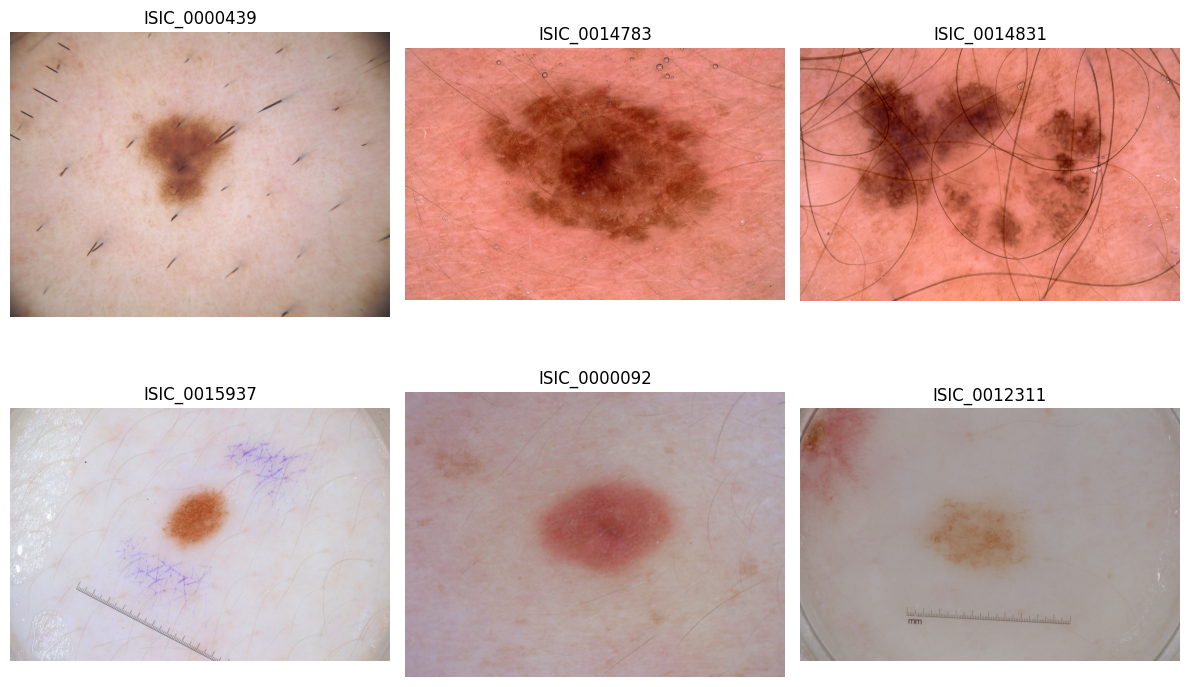

In [30]:
import cv2
import matplotlib.pyplot as plt

images_poils = quality[
    quality["C1_hair"] == 1
].sample(n=6, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, images_poils.iterrows()):
    image = cv2.imread(row["image_path"])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(row["image_id"])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [31]:
for f in sorted(RESULTS.glob("*.csv")):
    print(f.name, ":", round(f.stat().st_size / 1024, 1), "Ko")

artifact_labels_reference.csv : 382.6 Ko
classification_summary.csv : 0.2 Ko
image_quality_labels.csv : 367.4 Ko
isic2018_image_catalog.csv : 347.1 Ko


In [32]:
import shutil

archive = shutil.make_archive(
    "/kaggle/working/ISIC2018_classification",
    "zip",
    root_dir=PROJECT,
    base_dir="results"
)

print("Archive créée :", archive)

Archive créée : /kaggle/working/ISIC2018_classification.zip


In [33]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")

RESULTS = PROJECT / "results"
MODELS = PROJECT / "models"

RESULTS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

# Nous récupérons les annotations des artefacts déjà importées.
df = pd.read_csv(
    RESULTS / "artifact_labels_reference.csv"
)

ARTIFACTS = [
    "hair",
    "gel_bubble",
    "gel_border",
    "ruler",
    "dark_corner",
    "ink",
    "patches"
]

# Vérifier la présence des colonnes nécessaires
required = ["image_id", "image_path"] + ARTIFACTS

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Colonnes manquantes : {missing}")

# Vérifier les annotations
for col in ARTIFACTS:
    assert df[col].notna().all(), f"Annotations manquantes : {col}"
    assert set(df[col].unique()).issubset({0, 1}), col

assert df["image_id"].is_unique
assert df["image_path"].map(lambda p: Path(p).is_file()).all()

print("Images disponibles :", len(df))
print("Annotations chargées :", ARTIFACTS)

display(df.head())

Images disponibles : 2594
Annotations chargées : ['hair', 'gel_bubble', 'gel_border', 'ruler', 'dark_corner', 'ink', 'patches']


,image_id,image_path,hair,gel_bubble,gel_border,ruler,dark_corner,ink,patches
0,ISIC_0000000,/kaggle/input/datasets/tschandl/isic2018-chall...,0,0,0,0,0,0,0
1,ISIC_0000001,/kaggle/input/datasets/tschandl/isic2018-chall...,1,1,0,0,0,0,0
2,ISIC_0000003,/kaggle/input/datasets/tschandl/isic2018-chall...,1,1,0,0,0,0,0
3,ISIC_0000004,/kaggle/input/datasets/tschandl/isic2018-chall...,1,1,0,1,1,0,0
4,ISIC_0000006,/kaggle/input/datasets/tschandl/isic2018-chall...,0,0,0,0,1,0,0


In [34]:
from sklearn.model_selection import train_test_split

# 70 % Train, 30 % temporaire
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["hair"]
)

# Les 30 % restants deviennent :
# 15 % Validation et 15 % Test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["hair"]
)

splits = {
    "train": train_df,
    "val": val_df,
    "test": test_df
}

# Sécurité : aucun identifiant partagé entre les ensembles
ids = {
    name: set(part["image_id"])
    for name, part in splits.items()
}

assert ids["train"].isdisjoint(ids["val"])
assert ids["train"].isdisjoint(ids["test"])
assert ids["val"].isdisjoint(ids["test"])

for name, part in splits.items():
    part = part.sort_values("image_id").reset_index(drop=True)

    part.to_csv(
        RESULTS / f"{name}_artifacts.csv",
        index=False
    )

    splits[name] = part

    print(f"{name.upper()} : {len(part)} images")

print("\nDivision terminée et enregistrée.")

TRAIN : 1815 images
VAL : 389 images
TEST : 390 images

Division terminée et enregistrée.


In [35]:
distribution = pd.DataFrame({
    name: part[ARTIFACTS].mean()
    for name, part in splits.items()
})

display((distribution * 100).round(1))

,train,val,test
hair,58.5,58.6,58.5
gel_bubble,48.4,50.6,49.0
gel_border,25.4,25.7,30.3
ruler,49.2,45.8,54.6
dark_corner,37.2,37.8,35.1
ink,16.6,15.7,20.5
patches,7.2,9.0,5.4


In [36]:
%%writefile /kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_features.py

import cv2
import numpy as np


def line_kernel(size, angle):
    """Construire un élément structurant linéaire orienté."""

    k = np.zeros((size, size), dtype=np.uint8)
    c = size // 2
    a = np.deg2rad(angle)

    dx = round(c * np.cos(a))
    dy = round(c * np.sin(a))

    cv2.line(
        k, (c-dx, c-dy), (c+dx, c+dy), 1, 1
    )

    return k


def extract_hair_features(image_rgb):
    """
    Extraire des descripteurs mathématiques
    liés aux structures sombres fines de l'image.

    Cette fonction ne nettoie PAS l'image.
    Elle fournit les caractéristiques au classificateur.
    """

    # Même taille d'analyse pour toutes les images
    image = cv2.resize(
        image_rgb, (256, 256),
        interpolation=cv2.INTER_AREA
    )

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    responses = []

    # Fermetures morphologiques directionnelles
    for angle in [0, 45, 90, 135]:

        kernel = line_kernel(17, angle)

        closed = cv2.morphologyEx(
            gray, cv2.MORPH_CLOSE, kernel
        )

        blackhat = cv2.subtract(closed, gray)
        responses.append(blackhat)

    response = np.maximum.reduce(responses)

    # Masque de structures sombres candidates
    mask = (response > 18).astype(np.uint8)

    # Analyse des composantes connexes
    count, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(mask, 8)
    )

    areas = []
    elongations = []
    linear_areas = []

    for i in range(1, count):

        x, y, w, h, area = stats[i]

        if area < 3:
            continue

        elongation = max(w, h) / max(1, min(w, h))

        areas.append(area)
        elongations.append(elongation)

        if elongation >= 3:
            linear_areas.append(area)

    # Caractéristiques numériques
    features = [
        float(gray.mean()),
        float(gray.std()),

        float(response.mean()),
        float(response.std()),
        float(np.percentile(response, 90)),
        float(np.percentile(response, 95)),
        float(np.percentile(response, 99)),

        float(mask.mean()),
        float(len(areas)),
        float(np.mean(areas)) if areas else 0.0,
        float(max(areas)) if areas else 0.0,

        float(np.mean(elongations)) if elongations else 0.0,
        float(max(elongations)) if elongations else 0.0,

        float(sum(linear_areas) / mask.size),
    ]

    return np.asarray(features, dtype=np.float32)


FEATURE_NAMES = [
    "gray_mean",
    "gray_std",
    "blackhat_mean",
    "blackhat_std",
    "blackhat_p90",
    "blackhat_p95",
    "blackhat_p99",
    "candidate_pixel_ratio",
    "component_count",
    "mean_component_area",
    "max_component_area",
    "mean_elongation",
    "max_elongation",
    "linear_component_area_ratio"
]

Writing /kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_features.py


In [37]:
import sys
import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

sys.path.insert(0, str(PROJECT))

from src.hair_features import (
    extract_hair_features,
    FEATURE_NAMES
)

def construire_features(part):
    X = []

    for path in tqdm(part["image_path"], desc="Extraction"):

        image_bgr = cv2.imread(str(path))

        if image_bgr is None:
            raise FileNotFoundError(path)

        image_rgb = cv2.cvtColor(
            image_bgr, cv2.COLOR_BGR2RGB
        )

        X.append(extract_hair_features(image_rgb))

    return np.asarray(X, dtype=np.float32)


X_train = construire_features(splits["train"])
X_val = construire_features(splits["val"])
X_test = construire_features(splits["test"])

y_train = splits["train"]["hair"].to_numpy(dtype=int)
y_val = splits["val"]["hair"].to_numpy(dtype=int)
y_test = splits["test"]["hair"].to_numpy(dtype=int)

print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

Extraction:   0%|          | 0/1815 [00:00<?, ?it/s]

Extraction:   0%|          | 0/389 [00:00<?, ?it/s]

Extraction:   0%|          | 0/390 [00:00<?, ?it/s]

Train : (1815, 14)
Validation : (389, 14)
Test : (390, 14)


In [38]:
for name, X in [
    ("train", X_train),
    ("val", X_val),
    ("test", X_test)
]:
    features_df = pd.DataFrame(X, columns=FEATURE_NAMES)

    features_df.insert(
        0, "image_id",
        splits[name]["image_id"].to_numpy()
    )

    features_df.to_csv(
        RESULTS / f"{name}_hair_features.csv",
        index=False
    )

print("Caractéristiques sauvegardées.")

Caractéristiques sauvegardées.


Meilleur seuil de validation : 0.3
F1 Validation : 0.7427

=== TEST C1 : POILS ===
              precision    recall  f1-score   support

  Sans poils       0.75      0.15      0.25       162
  Avec poils       0.61      0.96      0.75       228

    accuracy                           0.63       390
   macro avg       0.68      0.56      0.50       390
weighted avg       0.67      0.63      0.54       390



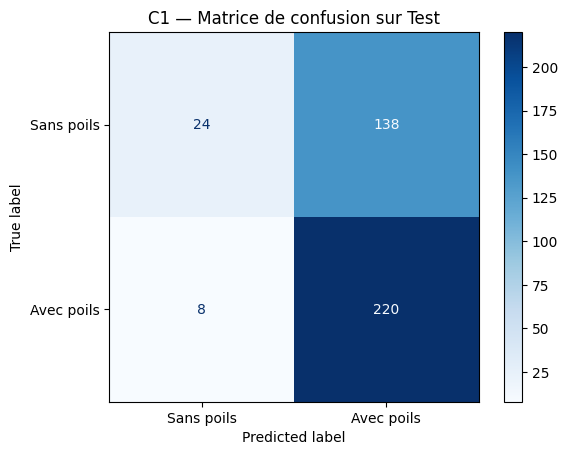

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import joblib
import json

model_hair = RandomForestClassifier(
    n_estimators=250,
    max_depth=12,
    min_samples_leaf=3,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

model_hair.fit(X_train, y_train)

# Probabilités sur validation
proba_val = model_hair.predict_proba(X_val)[:, 1]

# Calibration du seuil sur validation uniquement
threshold_candidates = np.arange(0.10, 0.91, 0.05)

scores = [
    f1_score(
        y_val,
        (proba_val >= t).astype(int),
        zero_division=0
    )
    for t in threshold_candidates
]

best_threshold = float(
    threshold_candidates[np.argmax(scores)]
)

print("Meilleur seuil de validation :", round(best_threshold, 3))
print("F1 Validation :", round(max(scores), 4))

# Évaluation finale sur test
proba_test = model_hair.predict_proba(X_test)[:, 1]

pred_test = (
    proba_test >= best_threshold
).astype(int)

print("\n=== TEST C1 : POILS ===")
print(classification_report(
    y_test,
    pred_test,
    target_names=["Sans poils", "Avec poils"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_test,
    display_labels=["Sans poils", "Avec poils"],
    cmap="Blues"
)

plt.title("C1 — Matrice de confusion sur Test")
plt.show()

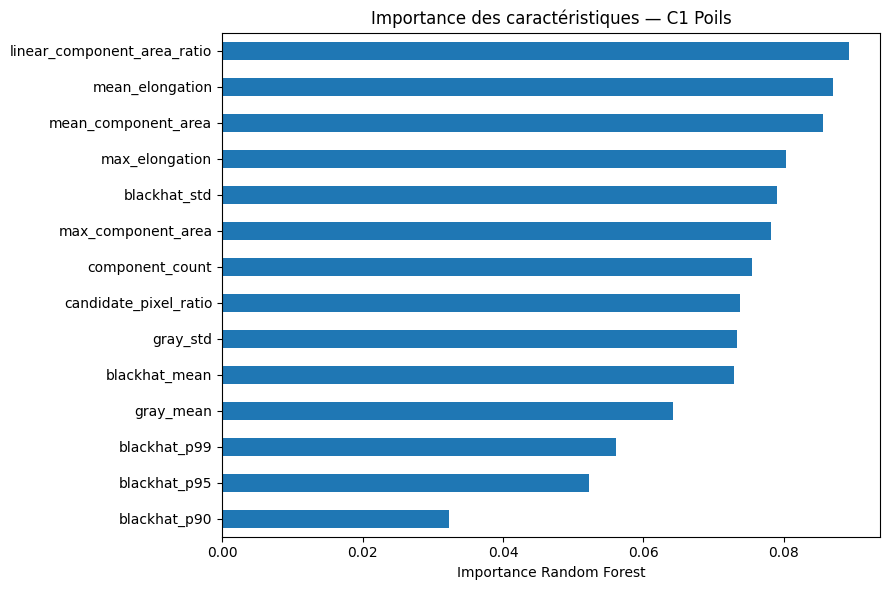

In [40]:
importance = pd.Series(
    model_hair.feature_importances_,
    index=FEATURE_NAMES
).sort_values()

plt.figure(figsize=(9, 6))
importance.plot(kind="barh")

plt.title("Importance des caractéristiques — C1 Poils")
plt.xlabel("Importance Random Forest")
plt.tight_layout()
plt.show()

In [42]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

resultats = []

for seuil in np.arange(0.10, 0.96, 0.05):

    predictions = (proba_val >= seuil).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    resultats.append({
        "seuil": round(float(seuil), 2),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "rappel": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "faux_positifs": fp,
        "faux_negatifs": fn,
        "specificite": tn / (tn + fp) if (tn + fp) else 0
    })

df_seuils = pd.DataFrame(resultats)

display(df_seuils.round(3))

,seuil,precision,rappel,f1,faux_positifs,faux_negatifs,specificite
0,0.10,0.586,1.000,0.739,161,0,0.000
1,0.15,0.586,1.000,0.739,161,0,0.000
2,0.20,0.592,0.991,0.741,156,2,0.031
3,0.25,0.598,0.978,0.742,150,5,0.068
4,0.30,0.613,0.943,0.743,136,13,0.155
5,0.35,0.633,0.868,0.732,115,30,0.286
6,0.40,0.657,0.781,0.713,93,50,0.422
7,0.45,0.711,0.732,0.721,68,61,0.578
8,0.50,0.740,0.636,0.684,51,83,0.683
9,0.55,0.764,0.526,0.623,37,108,0.770


In [43]:
RAPPEL_MIN = 0.97

candidats = df_seuils[
    df_seuils["rappel"] >= RAPPEL_MIN
]

if candidats.empty:
    raise ValueError("Aucun seuil ne satisfait le rappel demandé")

seuil_retenu = float(candidats["seuil"].max())

print("Seuil retenu :", seuil_retenu)

display(
    candidats[candidats["seuil"] == seuil_retenu]
)

Seuil retenu : 0.25


,seuil,precision,rappel,f1,faux_positifs,faux_negatifs,specificite
3,0.25,0.597855,0.97807,0.742097,150,5,0.068323


In [44]:
import numpy as np
import pandas as pd

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from xgboost import XGBClassifier

modeles = {
    "Random Forest": model_hair,

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),

    "SVM RBF": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            class_weight="balanced",
            random_state=42
        )
    )
}

In [45]:
RAPPEL_MIN = 0.97

resultats = []
modeles_entraines = {}

for nom, modele in modeles.items():

    print("Entraînement :", nom)

    if nom != "Random Forest":
        modele.fit(X_train, y_train)

    modeles_entraines[nom] = modele

    probabilites = modele.predict_proba(X_val)[:, 1]

    meilleur = None

    seuils = np.unique(
        np.concatenate(([0.0, 1.0], probabilites))
    )

    for seuil in seuils:

        pred = (probabilites >= seuil).astype(int)

        precision = precision_score(
            y_val, pred, zero_division=0
        )

        rappel = recall_score(
            y_val, pred, zero_division=0
        )

        f1 = f1_score(
            y_val, pred, zero_division=0
        )

        tn, fp, fn, tp = confusion_matrix(
            y_val, pred, labels=[0, 1]
        ).ravel()

        if rappel >= RAPPEL_MIN:

            candidat = {
                "Modele": nom,
                "Seuil": float(seuil),
                "Precision": precision,
                "Rappel": rappel,
                "F1": f1,
                "FP": int(fp),
                "FN": int(fn)
            }

            if (
                meilleur is None
                or candidat["FP"] < meilleur["FP"]
                or (
                    candidat["FP"] == meilleur["FP"]
                    and candidat["F1"] > meilleur["F1"]
                )
            ):
                meilleur = candidat

    resultats.append(meilleur)

comparaison = pd.DataFrame(resultats)

comparaison = comparaison.sort_values(
    ["FP", "F1"],
    ascending=[True, False]
)

display(comparaison.round(4))

Entraînement : Random Forest
Entraînement : Extra Trees
Entraînement : XGBoost
Entraînement : SVM RBF


,Modele,Seuil,Precision,Rappel,F1,FP,FN
3,SVM RBF,0.3680,0.6167,0.9737,0.7551,138,6
1,Extra Trees,0.3337,0.6082,0.9737,0.7487,143,6
0,Random Forest,0.2626,0.6011,0.9781,0.7446,148,5
2,XGBoost,0.1818,0.6000,0.9737,0.7425,148,6


=== SVM RBF — TEST FINAL ===
Seuil : 0.36796454589432065
              precision    recall  f1-score   support

  Sans poils       0.53      0.06      0.10       162
  Avec poils       0.59      0.96      0.73       228

    accuracy                           0.59       390
   macro avg       0.56      0.51      0.42       390
weighted avg       0.56      0.59      0.47       390



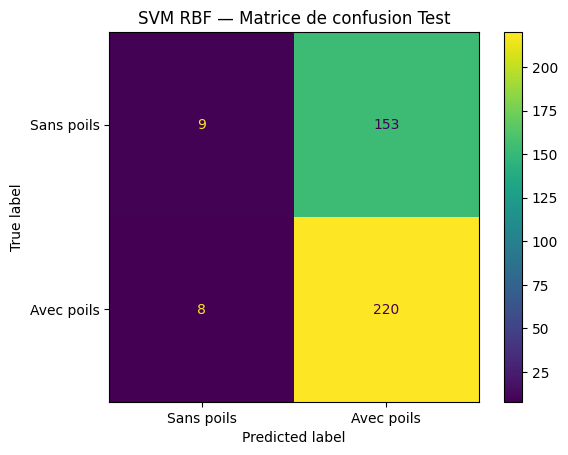

In [47]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Modèle sélectionné sur la validation
best_model = modeles_entraines["SVM RBF"]

# Seuil retenu lors de la comparaison
best_threshold = float(
    comparaison.loc[
        comparaison["Modele"] == "SVM RBF",
        "Seuil"
    ].iloc[0]
)

# Prédiction sur Test
proba_test_svm = best_model.predict_proba(X_test)[:, 1]
pred_test_svm = (proba_test_svm >= best_threshold).astype(int)

print("=== SVM RBF — TEST FINAL ===")
print("Seuil :", best_threshold)

print(classification_report(
    y_test,
    pred_test_svm,
    target_names=["Sans poils", "Avec poils"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_test_svm,
    display_labels=["Sans poils", "Avec poils"]
)

plt.title("SVM RBF — Matrice de confusion Test")
plt.show()

In [48]:
from pathlib import Path
import joblib
import json

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")
MODELS = PROJECT / "models"
MODELS.mkdir(parents=True, exist_ok=True)

# Modèles déjà entraînés
svm_model = modeles_entraines["SVM RBF"]
rf_model = modeles_entraines["Random Forest"]

# Seuils choisis sur la validation, pas sur le test
svm_threshold = float(
    comparaison.loc[
        comparaison["Modele"] == "SVM RBF", "Seuil"
    ].iloc[0]
)

rf_threshold = float(
    comparaison.loc[
        comparaison["Modele"] == "Random Forest", "Seuil"
    ].iloc[0]
)

# Enregistrer les deux modèles
joblib.dump(svm_model, MODELS / "hair_svm_rbf.joblib")
joblib.dump(rf_model, MODELS / "hair_random_forest.joblib")

# Enregistrer la configuration
config = {
    "task": "C1_hair_detection",
    "primary_model": "SVM RBF",
    "feature_names": FEATURE_NAMES,
    "image_size": [256, 256],
    "thresholds": {
        "SVM RBF": svm_threshold,
        "Random Forest": rf_threshold
    },
    "feature_extractor": "src.hair_features.extract_hair_features",
    "positive_label": 1,
    "negative_label": 0
}

with open(MODELS / "hair_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("SVM enregistré :", MODELS / "hair_svm_rbf.joblib")
print("Random Forest enregistré :", MODELS / "hair_random_forest.joblib")
print("Configuration enregistrée :", MODELS / "hair_config.json")

SVM enregistré : /kaggle/working/ISIC2018_pipeline_adaptatif/models/hair_svm_rbf.joblib
Random Forest enregistré : /kaggle/working/ISIC2018_pipeline_adaptatif/models/hair_random_forest.joblib
Configuration enregistrée : /kaggle/working/ISIC2018_pipeline_adaptatif/models/hair_config.json


In [49]:
%%writefile /kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_predictor.py

from pathlib import Path
import json
import joblib
import numpy as np

from src.hair_features import (
    extract_hair_features,
    FEATURE_NAMES
)


class HairPredictor:
    """
    Classificateur C1 — Présence de poils.

    Charge un modèle déjà entraîné et prédit
    si une nouvelle image nécessite potentiellement
    un nettoyage des poils.
    """

    def __init__(self, project_path, model_name="SVM RBF"):

        self.project = Path(project_path)

        with open(self.project / "models/hair_config.json") as f:
            config = json.load(f)

        if list(FEATURE_NAMES) != config["feature_names"]:
            raise ValueError(
                "Les caractéristiques ont changé depuis l'entraînement."
            )

        filenames = {
            "SVM RBF": "hair_svm_rbf.joblib",
            "Random Forest": "hair_random_forest.joblib"
        }

        if model_name not in filenames:
            raise ValueError("Modèle inconnu")

        self.model = joblib.load(
            self.project / "models" / filenames[model_name]
        )

        self.threshold = float(
            config["thresholds"][model_name]
        )

        self.model_name = model_name

    def predict_hair(self, image_rgb):

        features = extract_hair_features(image_rgb)

        score = float(
            self.model.predict_proba(
                features.reshape(1, -1)
            )[0, 1]
        )

        return {
            "classe": "C1_hair",
            "modele": self.model_name,
            "score": score,
            "seuil": self.threshold,
            "hair_detected": bool(score >= self.threshold)
        }

Writing /kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_predictor.py


In [50]:
import sys
import cv2

sys.path.insert(0, str(PROJECT))

from src.hair_predictor import HairPredictor

detecteur = HairPredictor(
    PROJECT,
    model_name="SVM RBF"
)

# Une image ISIC de ton jeu de test
image_path = splits["test"].iloc[0]["image_path"]

image_bgr = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

resultat = detecteur.predict_hair(image_rgb)

print(resultat)

{'classe': 'C1_hair', 'modele': 'SVM RBF', 'score': 0.3188214433780374, 'seuil': 0.36796454589432065, 'hair_detected': False}


In [51]:
import sys
import cv2

sys.path.insert(0, str(PROJECT))

from src.hair_predictor import HairPredictor

detecteur = HairPredictor(
    PROJECT,
    model_name="SVM RBF"
)

# Une image ISIC de ton jeu de test
image_path = splits["test"].iloc[0]["image_path"]

image_bgr = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

resultat = detecteur.predict_hair(image_rgb)

print(resultat)

{'classe': 'C1_hair', 'modele': 'SVM RBF', 'score': 0.3188214433780374, 'seuil': 0.36796454589432065, 'hair_detected': False}


In [52]:
import sys
import cv2

sys.path.insert(0, str(PROJECT))

from src.hair_predictor import HairPredictor

detecteur = HairPredictor(
    PROJECT,
    model_name="SVM RBF"
)

# Une image ISIC de ton jeu de test
image_path = splits["test"].iloc[0]["image_path"]

image_bgr = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

resultat = detecteur.predict_hair(image_rgb)

print(resultat)

{'classe': 'C1_hair', 'modele': 'SVM RBF', 'score': 0.3188214433780374, 'seuil': 0.36796454589432065, 'hair_detected': False}


In [53]:
for file in sorted((PROJECT / "src").glob("hair*.py")):
    print(file.name, ":", file.stat().st_size, "octets")

for file in sorted(MODELS.glob("hair*")):
    print(file.name, ":", file.stat().st_size, "octets")

hair_features.py : 2779 octets
hair_predictor.py : 1659 octets
hair_removal.py : 2217 octets
hair_config.json : 659 octets
hair_random_forest.joblib : 7284185 octets
hair_svm_rbf.joblib : 189741 octets


Image : ISIC_0000006
Annotation réelle : 0
Classe prédite : 0
✅ Prédiction correcte


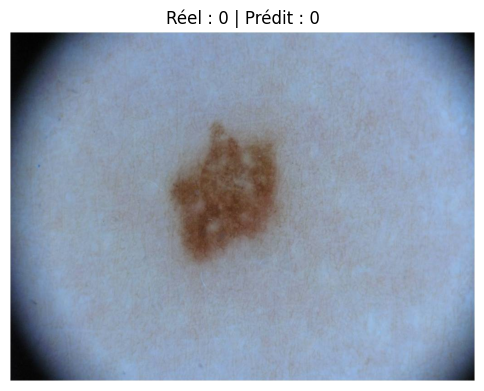

In [54]:
import matplotlib.pyplot as plt

# Image utilisée pour la prédiction
ligne = splits["test"].iloc[0]

# Annotation de référence Bissoto
vraie_classe = int(ligne["hair"])

# Prédiction du SVM
classe_predite = int(resultat["hair_detected"])

print("Image :", ligne["image_id"])
print("Annotation réelle :", vraie_classe)
print("Classe prédite :", classe_predite)

if vraie_classe == classe_predite:
    print("✅ Prédiction correcte")
else:
    print("❌ Prédiction incorrecte")

plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.title(
    f"Réel : {vraie_classe} | "
    f"Prédit : {classe_predite}"
)
plt.axis("off")
plt.show()

In [55]:
from src.hair_removal import dullrazor

if resultat["hair_detected"]:

    originale, response, masque, image_nettoyee = dullrazor(
        image_rgb
    )

    print("✅ Nettoyage DullRazor + Telea appliqué")

else:
    image_nettoyee = image_rgb.copy()

    print("Aucun nettoyage nécessaire selon le modèle")

Aucun nettoyage nécessaire selon le modèle


In [56]:
from pathlib import Path
import joblib
import json

PROJECT = Path("/kaggle/working/ISIC2018_pipeline_adaptatif")
MODELS = PROJECT / "models"
MODELS.mkdir(parents=True, exist_ok=True)

# Récupérer le SVM entraîné
svm = modeles_entraines["SVM RBF"]

# Récupérer le seuil validé
seuil = float(
    comparaison.loc[
        comparaison["Modele"] == "SVM RBF",
        "Seuil"
    ].iloc[0]
)

# Enregistrer le modèle
joblib.dump(
    svm,
    MODELS / "hair_svm_rbf.joblib"
)

# Enregistrer la configuration
config = {
    "model": "SVM RBF",
    "class": "C1_hair",
    "threshold": seuil,
    "feature_names": FEATURE_NAMES
}

with open(MODELS / "hair_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Modèle et configuration sauvegardés.")
print("Seuil :", seuil)

Modèle et configuration sauvegardés.
Seuil : 0.36796454589432065


In [57]:
import joblib
import numpy as np

modele_recharge = joblib.load(
    MODELS / "hair_svm_rbf.joblib"
)

score_original = svm.predict_proba(X_test[:5])[:, 1]
score_recharge = modele_recharge.predict_proba(X_test[:5])[:, 1]

assert np.allclose(score_original, score_recharge)

print("Modèle rechargé avec succès !")
print("Prédictions identiques :", score_recharge)

Modèle rechargé avec succès !
Prédictions identiques : [0.31882144 0.68642234 0.74254863 0.64283308 0.46903655]


In [58]:
%%writefile /kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_predictor.py

from pathlib import Path
import json
import joblib
import numpy as np

from src.hair_features import extract_hair_features, FEATURE_NAMES


class HairPredictor:
    def __init__(self, project_path):
        project = Path(project_path)

        with open(project / "models/hair_config.json") as f:
            config = json.load(f)

        if FEATURE_NAMES != config["feature_names"]:
            raise ValueError("Caractéristiques incompatibles avec le modèle")

        self.threshold = float(config["threshold"])
        self.model = joblib.load(
            project / "models/hair_svm_rbf.joblib"
        )

    def predict_hair(self, image_rgb):
        features = extract_hair_features(image_rgb)

        score = float(
            self.model.predict_proba(
                features.reshape(1, -1)
            )[0, 1]
        )

        return {
            "score": score,
            "threshold": self.threshold,
            "hair_detected": bool(score >= self.threshold)
        }

Overwriting /kaggle/working/ISIC2018_pipeline_adaptatif/src/hair_predictor.py


In [59]:
from zipfile import ZipFile, ZIP_DEFLATED

export_files = [
    "src/__init__.py",
    "src/hair_features.py",
    "src/hair_predictor.py",
    "src/hair_removal.py",
    "models/hair_svm_rbf.joblib",
    "models/hair_config.json"
]

zip_path = Path("/kaggle/working/C1_hair_model_github.zip")

with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
    for name in export_files:
        fichier = PROJECT / name

        if not fichier.is_file():
            raise FileNotFoundError(fichier)

        z.write(fichier, arcname=name)

print("Export créé :", zip_path)
print("Taille :", round(zip_path.stat().st_size / 1024 / 1024, 2), "Mo")

Export créé : /kaggle/working/C1_hair_model_github.zip
Taille : 0.08 Mo
